# 11b — Importância das conexões com XGBoost (TEA / ABIDE I)

Este notebook calcula a importância nativa do XGBoost para todas as **19.900 conexões do CC200**. Usa os mesmos folds externos por centro e, em cada fold, reajusta o XGBoost somente com o treino e os hiperparâmetros registrados pelo Notebook 08.

- Entrada do modelo: exclusivamente a matriz de conectividade funcional `X` (19.900 colunas).
- Alvo: diagnóstico binário `y` (controle = 0, TEA = 1). Idade, sexo, QI e demais fenótipos não são carregados como preditores.
- As 19.900 colunas são fornecidas ao estimador em cada fold; nenhuma é removida da matriz de treino. Conexões sem uso em árvores recebem importância zero e permanecem nos arquivos. O parâmetro original `colsample_bytree=0.8` é preservado e amostra colunas internamente por árvore, sem fazer uma seleção global de atributos.
- Métricas do XGBoost: `Gain` (ganho médio dos splits), `Weight` (número de splits) e `Cover` (cobertura média dos splits).
- Para cada métrica, calcula-se ranking completo, top 30 por fold, frequência no top 30 entre folds e top 30 agregado pela média da importância nos folds.

A posição das ROIs acompanha exatamente a vetorização do Notebook 07: `np.triu_indices(200, k=1)`, triângulo superior estrito, por linha. A nomenclatura `ROI 001` … `ROI 200` identifica a posição do parcel no CC200; não atribui nomes anatômicos.

As importâncias são descritivas do modelo ajustado e não indicam causalidade. Os folds compartilham dados de treino, portanto a frequência entre folds não equivale a validação independente.

In [1]:
# 1. Projeto, dados e auditoria dos folds
import ast
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

_raiz = Path.cwd().resolve()
for _c in (_raiz, *_raiz.parents):
    if (_c / 'src' / 'config.py').is_file():
        _raiz = _c
        break
else:
    raise RuntimeError('Não encontrei src/config.py. Abra a pasta do projeto no VS Code.')
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))

from src.config import PATHS, SEED, criar_pastas
from src import avaliacao as av

criar_pastas()
PASTA_RES = Path(PATHS['results'])
PASTA_FIG = Path(PATHS['figures'])
PASTA_RES.mkdir(parents=True, exist_ok=True)
PASTA_FIG.mkdir(parents=True, exist_ok=True)

ARQ_DATASET = Path(PATHS['processed']) / 'dataset_abide_processado.pkl'
d = av.carregar_dataset(ARQ_DATASET)
X = d['X']
y = d['y']
fold_id = d['fold_id']
sites = d['sites']
N_FEATURES = 19_900
N_ROIS = 200
TOP_K = 30
METRICAS_IMPORTANCIA = ('gain', 'weight', 'cover')

if X.shape[1] != N_FEATURES:
    raise ValueError(f'Esperadas {N_FEATURES} conexões CC200; encontradas {X.shape[1]}.')
if av.n_rois_de(X.shape[1]) != N_ROIS:
    raise ValueError('O número de conexões não corresponde a 200 ROIs do CC200.')
roi_i, roi_j = np.triu_indices(N_ROIS, k=1)
if len(roi_i) != N_FEATURES:
    raise RuntimeError('A ordem de vetorização não gera 19.900 conexões.')

folds = sorted(np.unique(fold_id).tolist())
print(f'X: {X.shape} | alvo: diagnóstico binário | folds externos: {folds}')
print('Preditores usados: somente as 19.900 conexões funcionais; sem seleção de variáveis.')
display(av.resumo_folds(d))

X: (871, 19900) | alvo: diagnóstico binário | folds externos: [0, 1, 2, 3, 4]
Preditores usados: somente as 19.900 conexões funcionais; sem seleção de variáveis.


,fold,n_treino,n_teste,controles_teste,casos_teste,controles_treino,casos_treino,sites_teste,sobreposicao_sites,duas_classes_no_teste
0,0,830,41,19,22,449,381,YALE,0,True
1,1,698,173,101,72,367,331,"KKI, OLIN, SBL, UM_1",0,True
2,2,706,165,91,74,377,329,"CALTECH, LEUVEN_1, LEUVEN_2, PITT, TRINITY",0,True
3,3,547,324,175,149,293,254,"CMU, NYU, OHSU, SDSU, STANFORD, UCLA_1",0,True
4,4,703,168,82,86,386,317,"MAX_MUN, UCLA_2, UM_2, USM",0,True


In [2]:
# 2. Ler o XGBoost e os hiperparâmetros registrados por fold no Notebook 08
ARQ_08 = PASTA_RES / '08_resultados_long.csv'
if not ARQ_08.is_file():
    raise FileNotFoundError('Results/08_resultados_long.csv não encontrado. Execute o Notebook 08 primeiro.')

r08 = pd.read_csv(ARQ_08)
r08 = r08[(r08['modelo'] == 'XGBoost') & (r08['tipo'] == 'externo')].copy()
if 'semente' not in r08 or r08.empty:
    raise ValueError('Não encontrei resultados externos do XGBoost no arquivo do Notebook 08.')

sementes = sorted(r08['semente'].dropna().astype(int).unique().tolist())
if len(sementes) != 1:
    raise ValueError(f'Esperada uma semente do XGBoost para reproduzir o Notebook 08; encontradas {sementes}.')
SEMENTE_XGB = sementes[0]
r08 = r08[r08['semente'].astype(int) == SEMENTE_XGB].copy()
if set(r08['fold'].astype(int)) != set(folds):
    raise ValueError('Os folds do dataset não correspondem aos folds XGBoost registrados no Notebook 08.')
if r08.duplicated(['fold']).any():
    raise ValueError('Há mais de um resultado XGBoost por fold/ semente no Notebook 08.')

PARAMS_POR_FOLD = {}
AUC_08_POR_FOLD = {}
for f in folds:
    linha = r08[r08['fold'].astype(int) == int(f)].iloc[0]
    params = ast.literal_eval(str(linha['params']))
    if not isinstance(params, dict):
        raise TypeError(f'Hiperparâmetros inválidos no fold {f}: {params!r}')
    if int(linha['k_interno']) > 0 and not params:
        raise ValueError(f'Fold {f}: busca interna viável, mas parâmetros não foram registrados.')
    PARAMS_POR_FOLD[f] = params
    AUC_08_POR_FOLD[f] = float(linha['auc_roc'])

print(f'Semente reproduzida: {SEMENTE_XGB}')
display(pd.DataFrame({
    'fold': folds,
    'hiperparâmetros do Notebook 08': [str(PARAMS_POR_FOLD[f]) for f in folds],
    'AUC de teste registrada no Notebook 08': [AUC_08_POR_FOLD[f] for f in folds],
}))

Semente reproduzida: 42


,fold,hiperparâmetros do Notebook 08,AUC de teste registrada no Notebook 08
0,0,"{'n_estimators': 300, 'max_depth': 3, 'learnin...",0.686603
1,1,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",0.688944
2,2,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",0.672706
3,3,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",0.676242
4,4,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",0.728871


In [3]:
# 3. Ajustar um XGBoost por fold e extrair Gain, Weight e Cover no treino
# get_score omite atributos não usados; os reintroduzimos explicitamente com importância zero.
resultados_fold = []

for f in folds:
    idx_teste = np.flatnonzero(fold_id == f)
    idx_treino = np.flatnonzero(fold_id != f)
    X_treino, y_treino = X[idx_treino], y[idx_treino]

    inicio = time.time()
    modelo = av.criar_modelo(
        'XGBoost', y_treino, seed=SEMENTE_XGB, params=PARAMS_POR_FOLD[f]
    )
    modelo.fit(X_treino, y_treino)
    booster = modelo.get_booster()

    for metrica in METRICAS_IMPORTANCIA:
        scores = booster.get_score(importance_type=metrica)
        valores = np.zeros(N_FEATURES, dtype=np.float64)
        for nome_feature, valor in scores.items():
            if not nome_feature.startswith('f'):
                raise ValueError(f'Nome inesperado de feature XGBoost: {nome_feature!r}')
            indice = int(nome_feature[1:])
            if indice < 0 or indice >= N_FEATURES:
                raise IndexError(f'Índice de feature fora de 0..{N_FEATURES - 1}: {indice}')
            valores[indice] = float(valor)

        # Desempate determinístico pela posição original da conexão.
        ordem = np.lexsort((np.arange(N_FEATURES), -valores))
        ranking = np.empty(N_FEATURES, dtype=np.int32)
        ranking[ordem] = np.arange(1, N_FEATURES + 1, dtype=np.int32)
        roi_a_idx = roi_i + 1
        roi_b_idx = roi_j + 1
        roi_a = np.array([f'ROI {k:03d}' for k in roi_a_idx])
        roi_b = np.array([f'ROI {k:03d}' for k in roi_b_idx])

        resultados_fold.append(pd.DataFrame({
            'fold': int(f),
            'metrica': metrica.title(),
            'feature_index_0based': np.arange(N_FEATURES, dtype=np.int32),
            'roi_a_index_1based': roi_a_idx,
            'roi_b_index_1based': roi_b_idx,
            'roi_a': roi_a,
            'roi_b': roi_b,
            'conexao': [f'{a} — {b}' for a, b in zip(roi_a, roi_b)],
            'importancia': valores,
            'ranking_no_fold': ranking,
            # Evita contar conexões empatadas em zero como selecionadas no top 30.
            'no_top30_no_fold': (ranking <= TOP_K) & (valores > 0),
            'n_treino': len(idx_treino),
            'n_teste': len(idx_teste),
        }))

    print(
        f'Fold {f}: treino={len(idx_treino)} | teste={len(idx_teste)} | '
        f'XGBoost ajustado em {(time.time() - inicio) / 60:.1f} min'
    )

df_por_fold = pd.concat(resultados_fold, ignore_index=True)
if len(df_por_fold) != len(folds) * len(METRICAS_IMPORTANCIA) * N_FEATURES:
    raise RuntimeError('A tabela por fold não contém todas as features e métricas.')
print(f'Importâncias preservadas: {len(df_por_fold):,} linhas (fold × métrica × conexão).')

Fold 0: treino=830 | teste=41 | XGBoost ajustado em 5.9 min
Fold 1: treino=698 | teste=173 | XGBoost ajustado em 5.5 min
Fold 2: treino=706 | teste=165 | XGBoost ajustado em 6.5 min
Fold 3: treino=547 | teste=324 | XGBoost ajustado em 9.0 min
Fold 4: treino=703 | teste=168 | XGBoost ajustado em 5.0 min
Importâncias preservadas: 298,500 linhas (fold × métrica × conexão).


In [4]:
# 4. Ranking agregado completo, frequência no top 30 e resumo por fold
metadados = pd.DataFrame({
    'feature_index_0based': np.arange(N_FEATURES, dtype=np.int32),
    'roi_a_index_1based': roi_i + 1,
    'roi_b_index_1based': roi_j + 1,
})
metadados['roi_a'] = metadados['roi_a_index_1based'].map(lambda k: f'ROI {k:03d}')
metadados['roi_b'] = metadados['roi_b_index_1based'].map(lambda k: f'ROI {k:03d}')
metadados['conexao'] = metadados['roi_a'] + ' — ' + metadados['roi_b']

agregados = {}
tops = []
for metrica in ('Gain', 'Weight', 'Cover'):
    sub = df_por_fold[df_por_fold['metrica'] == metrica]
    agg = (sub.groupby('feature_index_0based', sort=False)
           .agg(importancia_media=('importancia', 'mean'),
                importancia_dp=('importancia', 'std'),
                importancia_mediana=('importancia', 'median'),
                folds_com_importancia=('importancia', lambda s: int((s > 0).sum())),
                frequencia_top30=('no_top30_no_fold', 'sum'))
           .reindex(range(N_FEATURES)).reset_index())
    agg = agg.sort_values(
        ['importancia_media', 'feature_index_0based'],
        ascending=[False, True], kind='stable'
    ).reset_index(drop=True)
    agg['ranking_media'] = np.arange(1, N_FEATURES + 1, dtype=np.int32)
    agregados[metrica] = agg

    top = agg.head(TOP_K).merge(metadados, on='feature_index_0based', how='left', validate='one_to_one')
    top.insert(0, 'metrica', metrica)
    top = top.rename(columns={
        'importancia_media': 'importancia_media_nos_folds',
        'importancia_dp': 'importancia_dp_entre_folds',
        'importancia_mediana': 'importancia_mediana_nos_folds',
        'ranking_media': 'ranking_agregado',
    })
    tops.append(top)

ranking_completo = metadados.copy()
for metrica, prefixo in [('Gain', 'gain'), ('Weight', 'weight'), ('Cover', 'cover')]:
    agg = agregados[metrica].rename(columns={
        'importancia_media': f'{prefixo}_media',
        'importancia_dp': f'{prefixo}_dp',
        'importancia_mediana': f'{prefixo}_mediana',
        'folds_com_importancia': f'{prefixo}_folds_com_importancia',
        'frequencia_top30': f'{prefixo}_frequencia_top30',
        'ranking_media': f'{prefixo}_ranking',
    })
    ranking_completo = ranking_completo.merge(agg, on='feature_index_0based', how='left', validate='one_to_one')

ranking_completo = ranking_completo.sort_values(['gain_ranking', 'feature_index_0based']).reset_index(drop=True)
top30_completo = pd.concat(tops, ignore_index=True)

# Resumo de cobertura das features e valores médios do top 30 em cada fold.
df_resumo_base = df_por_fold.assign(
    importancia_top30_aux=np.where(
        df_por_fold['no_top30_no_fold'], df_por_fold['importancia'], np.nan
    )
)
resumo_fold = (df_resumo_base.groupby(['fold', 'metrica'], as_index=False)
               .agg(features_com_importancia=('importancia', lambda s: int((s > 0).sum())),
                    importancia_media_top30=('importancia_top30_aux', 'mean'),
                    conexoes_no_top30=('no_top30_no_fold', 'sum')))
resumo_fold['importancia_media_top30'] = resumo_fold['importancia_media_top30'].fillna(0.0)
resumo_fold = resumo_fold.merge(
    r08[['fold', 'n_teste', 'auc_roc', 'params', 'semente']].rename(columns={
        'auc_roc': 'auc_teste_registrada_notebook08',
        'params': 'hiperparametros_notebook08',
        'semente': 'semente_notebook08',
    }), on='fold', how='left', validate='many_to_one'
)
resumo_fold['n_treino'] = [int((fold_id != f).sum()) for f in resumo_fold['fold']]
resumo_fold['n_teste'] = [int((fold_id == f).sum()) for f in resumo_fold['fold']]
resumo_fold['sites_teste'] = resumo_fold['fold'].map(
    lambda f: ', '.join(sorted(np.unique(sites[fold_id == f]).astype(str)))
)

ARQ_RANKING = PASTA_RES / '11b_xgb_importancia_ranking_completo.csv'
ARQ_POR_FOLD = PASTA_RES / '11b_xgb_importancia_por_fold.csv'
ARQ_TOP30 = PASTA_RES / '11b_xgb_top30_conexoes.csv'
ARQ_RESUMO = PASTA_RES / '11b_xgb_resumo_por_fold.csv'
ranking_completo.to_csv(ARQ_RANKING, index=False)
df_por_fold.to_csv(ARQ_POR_FOLD, index=False)
top30_completo.to_csv(ARQ_TOP30, index=False)
resumo_fold.to_csv(ARQ_RESUMO, index=False)

print('Top 30 agregado por média da importância; frequencia_top30 conta folds em que a conexão ficou entre as 30 com importância positiva:')
for metrica in ('Gain', 'Weight', 'Cover'):
    print(f'\n{metrica}')
    display(top30_completo[top30_completo['metrica'] == metrica].head(30))
print('\nResumo por fold e métrica:')
display(resumo_fold)
print('\nCSV salvos:')
for caminho in (ARQ_RANKING, ARQ_POR_FOLD, ARQ_TOP30, ARQ_RESUMO):
    print(caminho)

Top 30 agregado por média da importância; frequencia_top30 conta folds em que a conexão ficou entre as 30 com importância positiva:

Gain


,metrica,feature_index_0based,importancia_media_nos_folds,importancia_dp_entre_folds,importancia_mediana_nos_folds,folds_com_importancia,frequencia_top30,ranking_agregado,roi_a_index_1based,roi_b_index_1based,roi_a,roi_b,conexao
0,Gain,3549,12.091360,3.059646,10.665893,5,0,1,19,140,ROI 019,ROI 140,ROI 019 — ROI 140
1,Gain,11332,9.407951,12.924265,0.000000,2,2,2,69,148,ROI 069,ROI 148,ROI 069 — ROI 148
2,Gain,3335,9.165417,1.785846,8.662234,5,0,3,18,107,ROI 018,ROI 107,ROI 018 — ROI 107
3,Gain,12095,8.699432,8.571805,11.285604,3,1,4,75,146,ROI 075,ROI 146,ROI 075 — ROI 146
4,Gain,3349,8.529212,12.431463,2.277259,4,1,5,18,121,ROI 018,ROI 121,ROI 018 — ROI 121
5,Gain,3252,8.120973,16.328956,0.389548,3,1,6,18,24,ROI 018,ROI 024,ROI 018 — ROI 024
6,Gain,924,7.994882,7.881994,6.786646,4,0,7,5,140,ROI 005,ROI 140,ROI 005 — ROI 140
7,Gain,7238,7.936988,4.772045,10.257505,4,0,8,41,100,ROI 041,ROI 100,ROI 041 — ROI 100
8,Gain,1885,7.593855,6.596158,7.136791,4,1,9,10,141,ROI 010,ROI 141,ROI 010 — ROI 141
9,Gain,4807,7.504907,6.544131,9.779488,4,0,10,26,159,ROI 026,ROI 159,ROI 026 — ROI 159



Weight


,metrica,feature_index_0based,importancia_media_nos_folds,importancia_dp_entre_folds,importancia_mediana_nos_folds,folds_com_importancia,frequencia_top30,ranking_agregado,roi_a_index_1based,roi_b_index_1based,roi_a,roi_b,conexao
30,Weight,3549,28.0,36.428011,13.0,5,5,1,19,140,ROI 019,ROI 140,ROI 019 — ROI 140
31,Weight,9095,8.8,3.114482,8.0,5,4,2,53,127,ROI 053,ROI 127,ROI 053 — ROI 127
32,Weight,12936,8.0,10.000000,3.0,5,2,3,82,140,ROI 082,ROI 140,ROI 082 — ROI 140
33,Weight,9243,7.8,4.969909,6.0,5,4,4,54,129,ROI 054,ROI 129,ROI 054 — ROI 129
34,Weight,10580,7.6,3.507136,7.0,5,4,5,63,197,ROI 063,ROI 197,ROI 063 — ROI 197
35,Weight,18178,7.4,13.352902,1.0,3,2,6,141,190,ROI 141,ROI 190,ROI 141 — ROI 190
36,Weight,3378,6.2,9.444575,3.0,5,1,7,18,150,ROI 018,ROI 150,ROI 018 — ROI 150
37,Weight,15106,6.2,4.969909,7.0,4,3,8,102,160,ROI 102,ROI 160,ROI 102 — ROI 160
38,Weight,18043,6.0,6.204837,3.0,5,2,9,139,174,ROI 139,ROI 174,ROI 139 — ROI 174
39,Weight,3335,5.8,6.058052,2.0,5,2,10,18,107,ROI 018,ROI 107,ROI 018 — ROI 107



Cover


,metrica,feature_index_0based,importancia_media_nos_folds,importancia_dp_entre_folds,importancia_mediana_nos_folds,folds_com_importancia,frequencia_top30,ranking_agregado,roi_a_index_1based,roi_b_index_1based,roi_a,roi_b,conexao
60,Cover,3549,73.741113,12.060869,76.904816,5,4,1,19,140,ROI 019,ROI 140,ROI 019 — ROI 140
61,Cover,3335,68.212540,38.416718,76.097778,5,2,2,18,107,ROI 018,ROI 107,ROI 018 — ROI 107
62,Cover,8833,62.505849,49.480339,62.689232,4,2,3,51,160,ROI 051,ROI 160,ROI 051 — ROI 160
63,Cover,7910,59.869883,54.759689,61.423389,4,3,4,45,146,ROI 045,ROI 146,ROI 045 — ROI 146
64,Cover,9243,53.127469,23.996470,65.488770,5,2,5,54,129,ROI 054,ROI 129,ROI 054 — ROI 129
65,Cover,6881,50.225021,54.663009,44.738644,4,2,6,39,62,ROI 039,ROI 062,ROI 039 — ROI 062
66,Cover,11675,50.136257,16.453594,56.746571,5,1,7,72,104,ROI 072,ROI 104,ROI 072 — ROI 104
67,Cover,924,45.687235,39.138917,65.398880,4,1,8,5,140,ROI 005,ROI 140,ROI 005 — ROI 140
68,Cover,3349,44.918543,41.751367,52.785797,4,1,9,18,121,ROI 018,ROI 121,ROI 018 — ROI 121
69,Cover,3556,44.293521,50.127527,19.490639,4,2,10,19,147,ROI 019,ROI 147,ROI 019 — ROI 147



Resumo por fold e métrica:


,fold,metrica,features_com_importancia,importancia_media_top30,conexoes_no_top30,n_teste,auc_teste_registrada_notebook08,hiperparametros_notebook08,semente_notebook08,n_treino,sites_teste
0,0,Cover,1438,120.554655,30,41,0.686603,"{'n_estimators': 300, 'max_depth': 3, 'learnin...",42,830,YALE
1,0,Gain,1438,20.516100,30,41,0.686603,"{'n_estimators': 300, 'max_depth': 3, 'learnin...",42,830,YALE
2,0,Weight,1438,5.766667,30,41,0.686603,"{'n_estimators': 300, 'max_depth': 3, 'learnin...",42,830,YALE
3,1,Cover,1797,68.768020,30,173,0.688944,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",42,698,"KKI, OLIN, SBL, UM_1"
4,1,Gain,1797,17.844006,30,173,0.688944,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",42,698,"KKI, OLIN, SBL, UM_1"
5,1,Weight,1797,7.066667,30,173,0.688944,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",42,698,"KKI, OLIN, SBL, UM_1"
6,2,Cover,1855,83.662677,30,165,0.672706,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",42,706,"CALTECH, LEUVEN_1, LEUVEN_2, PITT, TRINITY"
7,2,Gain,1855,19.457137,30,165,0.672706,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",42,706,"CALTECH, LEUVEN_1, LEUVEN_2, PITT, TRINITY"
8,2,Weight,1855,6.666667,30,165,0.672706,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",42,706,"CALTECH, LEUVEN_1, LEUVEN_2, PITT, TRINITY"
9,3,Cover,3861,76.738226,30,324,0.676242,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",42,547,"CMU, NYU, OHSU, SDSU, STANFORD, UCLA_1"



CSV salvos:
/home/maria/TCC_TEA/Results/11b_xgb_importancia_ranking_completo.csv
/home/maria/TCC_TEA/Results/11b_xgb_importancia_por_fold.csv
/home/maria/TCC_TEA/Results/11b_xgb_top30_conexoes.csv
/home/maria/TCC_TEA/Results/11b_xgb_resumo_por_fold.csv


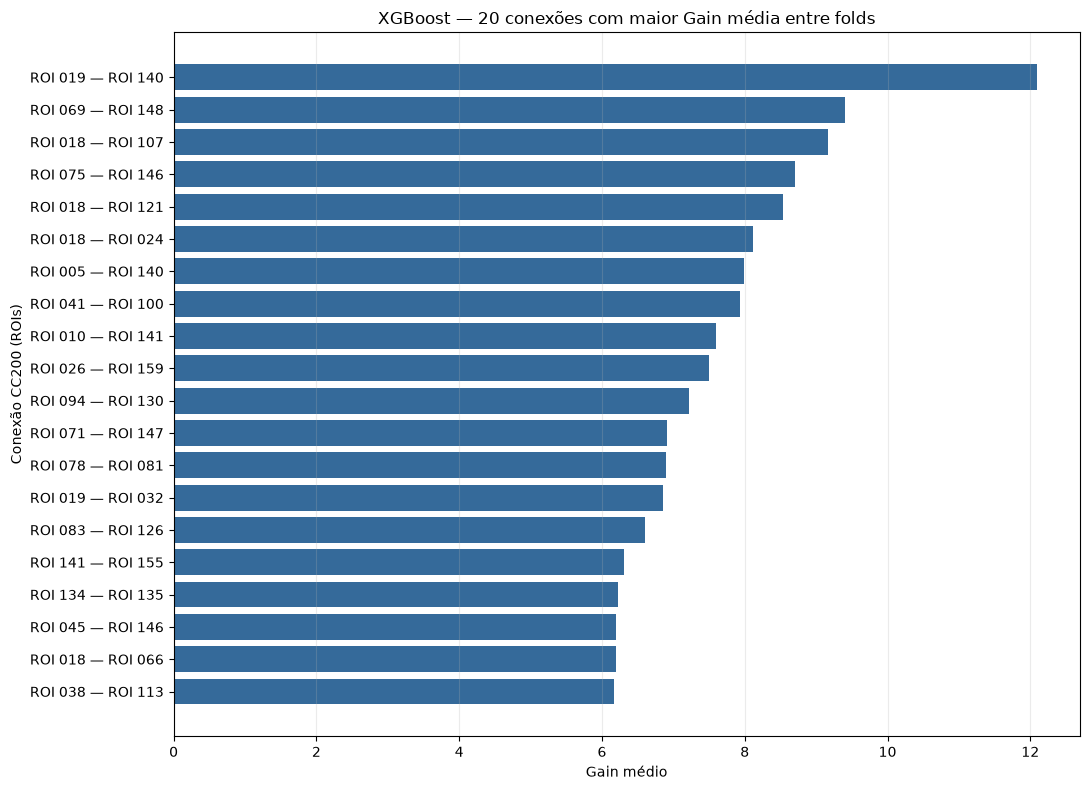

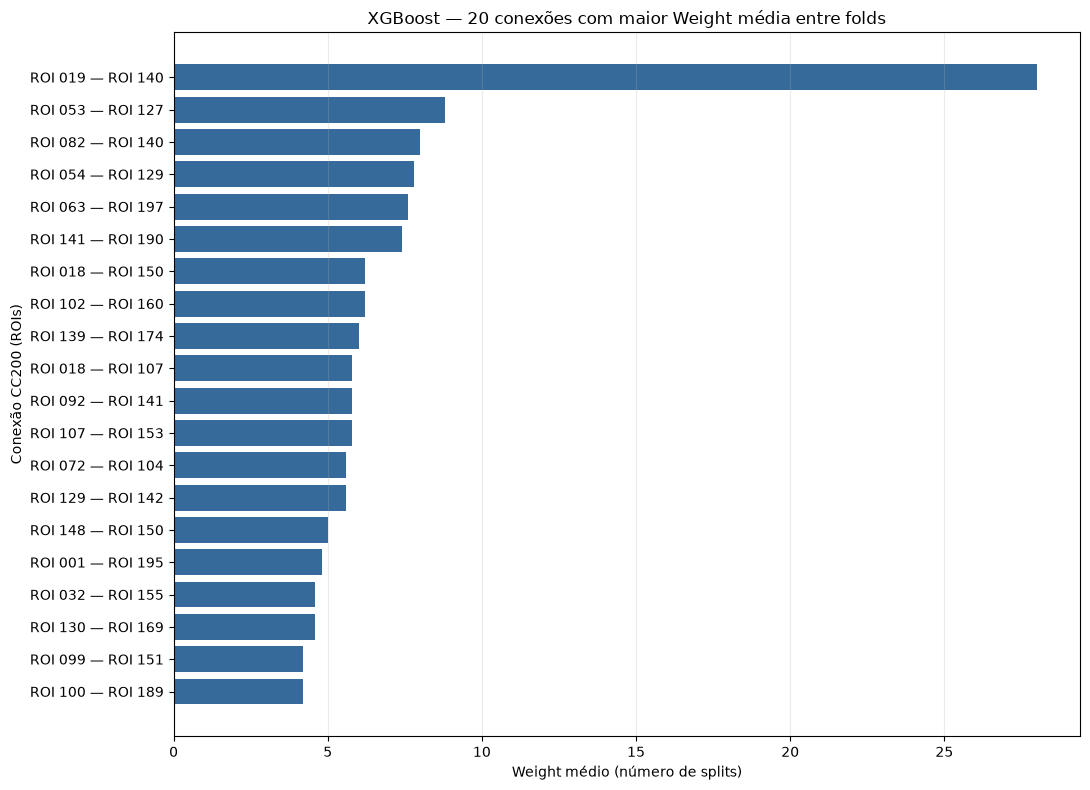

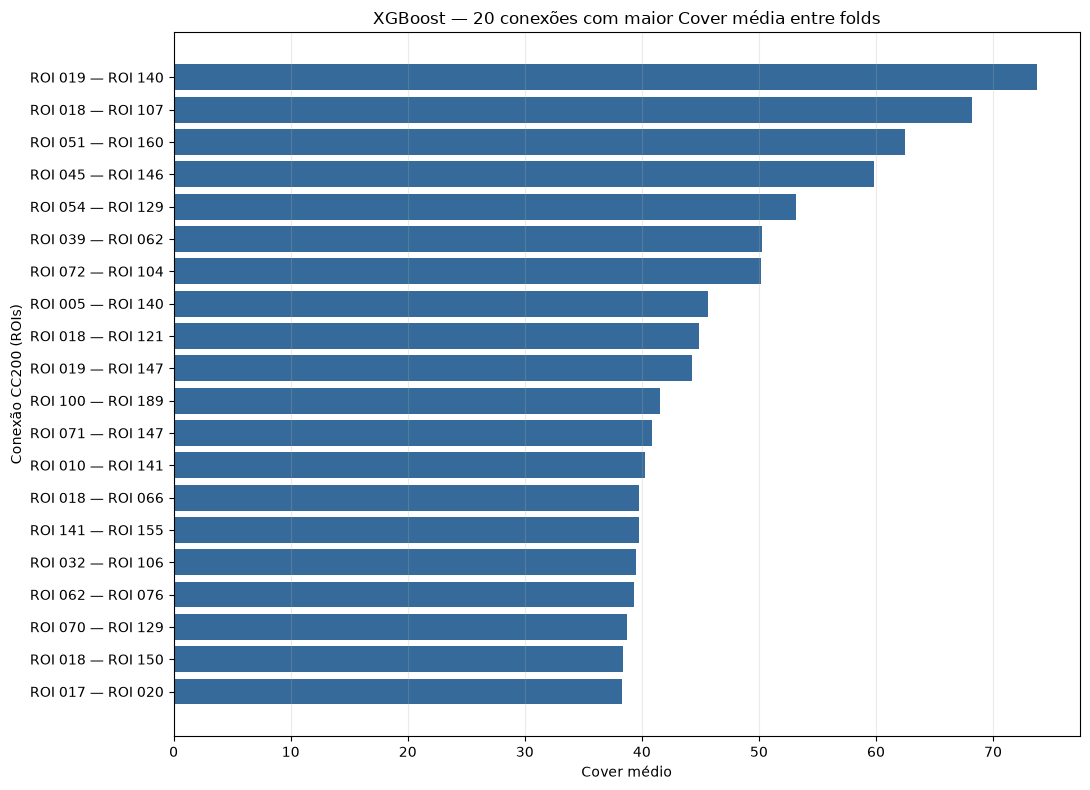

Figuras salvas:
/home/maria/TCC_TEA/Figures/11b_xgb_top20_gain.png
/home/maria/TCC_TEA/Figures/11b_xgb_top20_weight.png
/home/maria/TCC_TEA/Figures/11b_xgb_top20_cover.png


In [5]:
# 5. Gráficos: 20 conexões principais por média da importância nos folds
ARQS_FIG = []
for metrica, prefixo, eixo_x in [
    ('Gain', 'gain', 'Gain médio'),
    ('Weight', 'weight', 'Weight médio (número de splits)'),
    ('Cover', 'cover', 'Cover médio'),
]:
    tab = top30_completo[top30_completo['metrica'] == metrica].head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(11, 8))
    ax.barh(tab['conexao'], tab['importancia_media_nos_folds'], color='#356a9a')
    ax.set_xlabel(eixo_x)
    ax.set_ylabel('Conexão CC200 (ROIs)')
    ax.set_title(f'XGBoost — 20 conexões com maior {metrica} média entre folds')
    ax.grid(axis='x', alpha=0.25)
    fig.tight_layout()
    destino = PASTA_FIG / f'11b_xgb_top20_{prefixo}.png'
    fig.savefig(destino, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    ARQS_FIG.append(destino)

print('Figuras salvas:')
for caminho in ARQS_FIG:
    print(caminho)

## Interpretação e arquivos

O ranking agregado ordena todas as conexões pela média da importância nos folds, separadamente para `Gain`, `Weight` e `Cover`. A coluna `frequencia_top30` conta em quantos folds a conexão apareceu entre as 30 primeiras **com importância positiva** para aquela métrica. Valores zero continuam no ranking completo e no CSV por fold.

`11b_xgb_importancia_por_fold.csv` guarda o valor e o ranking de cada conexão em cada fold e métrica. `11b_xgb_resumo_por_fold.csv` resume número de conexões usadas, quantidade no top 30 e AUC de teste registrada no Notebook 08. A AUC é incluída como contexto; não participa do cálculo de importância.

Use `ROI 001` e `ROI 200` como posições das ROIs no vetor de 200 parcelas do CC200. Estes resultados não permitem inferência causal e podem refletir diferenças de centro, movimento ou protocolo.